# Experiment #6: Artificial Neural Network to Simulate the XOR Logic Gate

**Name:** Adithya Rajesh  |  **Class:** R3AI  |  **Roll No:** B25CTA07  |  **Date:** 13-10-2026

**Objective:** Design and implement an **Artificial Neural Network (ANN)** that learns the **XOR logic gate** using the **backpropagation algorithm**. Both **forward propagation** and **backpropagation** are implemented manually (only NumPy is used - no ML frameworks). We train the network, display the **error at every 100 iterations**, and finally show the **predicted output for all four input combinations**.

> XOR cannot be solved by a single-layer perceptron because it is **not linearly separable**. A network with a **hidden layer** is required.


## 1. The XOR Truth Table

| Input A | Input B | XOR Output |
|:-------:|:-------:|:----------:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |


In [1]:
import numpy as np

X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]], dtype=float)

y = np.array([[0],
              [1],
              [1],
              [0]], dtype=float)

print('Inputs (X):')
print(X)
print('Target (y):')
print(y)

Inputs (X):
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
Target (y):
[[0.]
 [1.]
 [1.]
 [0.]]


## 2. Network Architecture

A 3-layer feed-forward network:

- **Input layer:** 2 neurons (A and B)
- **Hidden layer:** 2 neurons
- **Output layer:** 1 neuron

Weights and biases are initialised with small random values so that the network can break symmetry during learning.


In [2]:
np.random.seed(16)

W1 = np.random.uniform(-1, 1, (2, 2))
b1 = np.random.uniform(-1, 1, (1, 2))
W2 = np.random.uniform(-1, 1, (2, 1))
b2 = np.random.uniform(-1, 1, (1, 1))

print('Initial W1:'); print(np.round(W1, 4))
print('Initial b1:'); print(np.round(b1, 4))
print('Initial W2:'); print(np.round(W2, 4))
print('Initial b2:'); print(np.round(b2, 4))

Initial W1:
[[-0.5534  0.0463]
 [ 0.1014 -0.9088]]
Initial b1:
[[-0.2785 -0.5538]]
Initial W2:
[[ 0.3775]
 [-0.6725]]
Initial b2:
[[-0.8594]]


## 3. Activation Function

We use the **sigmoid** function, which squashes any real value into the range (0, 1) and has a convenient derivative:

- `sigmoid(x) = 1 / (1 + e^-x)`
- `sigmoid'(x) = sigmoid(x) * (1 - sigmoid(x))`


In [3]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(a):
    return a * (1 - a)

## 4. Forward Propagation (Implemented Manually)

For each layer we compute the weighted sum `z = inputs . weights + bias`, then apply the activation.

- Hidden layer: `z1 = X.W1 + b1`, `a1 = sigmoid(z1)`
- Output layer: `z2 = a1.W2 + b2`, `a2 = sigmoid(z2)`


In [4]:
def forward(X, W1, b1, W2, b2):
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)
    return z1, a1, z2, a2

z1, a1, z2, a2 = forward(X, W1, b1, W2, b2)
print('Hidden layer output (a1):'); print(np.round(a1, 4))
print('Output layer (a2):'); print(np.round(a2, 4))

Hidden layer output (a1):
[[0.4308 0.365 ]
 [0.4558 0.1881]
 [0.3032 0.3758]
 [0.3251 0.1952]]
Output layer (a2):
[[0.2805]
 [0.3071]
 [0.2694]
 [0.2957]]


## 5. Backpropagation and Training (Implemented Manually)

The network is trained by minimising the **Mean Squared Error**:

`Error = (1/n) * sum( (y - a2)^2 )`

Backpropagation applies the chain rule to find how each weight affects the error, then updates the weights using **gradient descent**:

- Output error signal: `d2 = (a2 - y) * sigmoid'(a2)`
- Gradient for `W2`: `dW2 = a1^T . d2`
- Hidden error signal: `d1 = (d2 . W2^T) * sigmoid'(a1)`
- Gradient for `W1`: `dW1 = X^T . d1`
- Update: `W = W - learning_rate * dW`

The error is printed **after every 100 iterations**.


In [5]:
learning_rate = 0.5
iterations = 10000

errors = []

for i in range(1, iterations + 1):
    z1, a1, z2, a2 = forward(X, W1, b1, W2, b2)

    error = np.mean((y - a2) ** 2)
    errors.append(error)

    d2 = (a2 - y) * sigmoid_derivative(a2)
    dW2 = np.dot(a1.T, d2)
    db2 = np.sum(d2, axis=0, keepdims=True)

    d1 = np.dot(d2, W2.T) * sigmoid_derivative(a1)
    dW1 = np.dot(X.T, d1)
    db1 = np.sum(d1, axis=0, keepdims=True)

    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2
    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1

    if i % 100 == 0:
        print(f'Iteration {i:>6}  |  Error = {error:.6f}')

Iteration    100  |  Error = 0.249314
Iteration    200  |  Error = 0.247542
Iteration    300  |  Error = 0.242116
Iteration    400  |  Error = 0.226752
Iteration    500  |  Error = 0.200060
Iteration    600  |  Error = 0.176940
Iteration    700  |  Error = 0.159705
Iteration    800  |  Error = 0.140319
Iteration    900  |  Error = 0.087579
Iteration   1000  |  Error = 0.043591
Iteration   1100  |  Error = 0.024134
Iteration   1200  |  Error = 0.015515
Iteration   1300  |  Error = 0.011074
Iteration   1400  |  Error = 0.008470
Iteration   1500  |  Error = 0.006793
Iteration   1600  |  Error = 0.005637
Iteration   1700  |  Error = 0.004798
Iteration   1800  |  Error = 0.004164
Iteration   1900  |  Error = 0.003670
Iteration   2000  |  Error = 0.003276
Iteration   2100  |  Error = 0.002955
Iteration   2200  |  Error = 0.002688
Iteration   2300  |  Error = 0.002464
Iteration   2400  |  Error = 0.002272
Iteration   2500  |  Error = 0.002107
Iteration   2600  |  Error = 0.001964
Iteration   

Iteration   6200  |  Error = 0.000544
Iteration   6300  |  Error = 0.000533
Iteration   6400  |  Error = 0.000523
Iteration   6500  |  Error = 0.000512
Iteration   6600  |  Error = 0.000503
Iteration   6700  |  Error = 0.000493


Iteration   6800  |  Error = 0.000484
Iteration   6900  |  Error = 0.000475
Iteration   7000  |  Error = 0.000467
Iteration   7100  |  Error = 0.000458
Iteration   7200  |  Error = 0.000450


Iteration   7300  |  Error = 0.000443
Iteration   7400  |  Error = 0.000435
Iteration   7500  |  Error = 0.000428
Iteration   7600  |  Error = 0.000421
Iteration   7700  |  Error = 0.000414
Iteration   7800  |  Error = 0.000408


Iteration   7900  |  Error = 0.000402
Iteration   8000  |  Error = 0.000395
Iteration   8100  |  Error = 0.000390
Iteration   8200  |  Error = 0.000384
Iteration   8300  |  Error = 0.000378
Iteration   8400  |  Error = 0.000373
Iteration   8500  |  Error = 0.000367
Iteration   8600  |  Error = 0.000362
Iteration   8700  |  Error = 0.000357
Iteration   8800  |  Error = 0.000352
Iteration   8900  |  Error = 0.000347
Iteration   9000  |  Error = 0.000343
Iteration   9100  |  Error = 0.000338
Iteration   9200  |  Error = 0.000334
Iteration   9300  |  Error = 0.000330
Iteration   9400  |  Error = 0.000325
Iteration   9500  |  Error = 0.000321
Iteration   9600  |  Error = 0.000317
Iteration   9700  |  Error = 0.000313
Iteration   9800  |  Error = 0.000310
Iteration   9900  |  Error = 0.000306
Iteration  10000  |  Error = 0.000302


## 6. Error Reduction Over Iterations

The error decreases steadily as the network learns, confirming that backpropagation is correctly adjusting the weights.


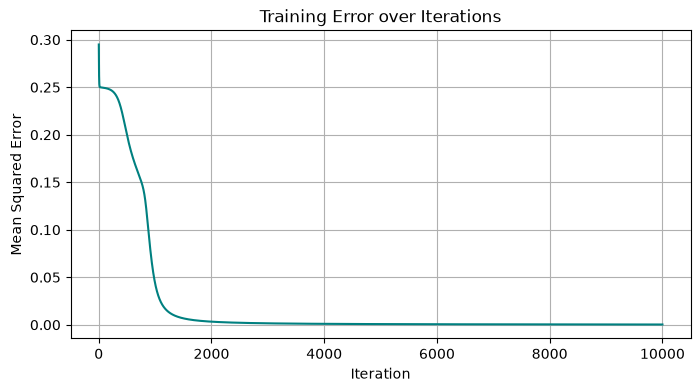

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(range(1, iterations + 1), errors, color='teal')
plt.title('Training Error over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Mean Squared Error')
plt.grid(True)
plt.show()

## 7. Predicted Outputs for All Input Combinations

We run forward propagation on all four input pairs using the final trained weights. The output is a continuous probability; rounding it gives the logical XOR result.


In [7]:
_, _, _, final_output = forward(X, W1, b1, W2, b2)
final_output = final_output.ravel()
rounded = np.round(final_output)

print('A   B  | Target | Predicted (raw) | Rounded | Correct?')
print('-' * 58)
for i in range(4):
    ok = 'Yes' if rounded[i] == y[i, 0] else 'No'
    print(f'{int(X[i,0])}   {int(X[i,1])}  |   {int(y[i,0])}    |     {final_output[i]:.4f}     |    {int(rounded[i])}    |  {ok}')

A   B  | Target | Predicted (raw) | Rounded | Correct?
----------------------------------------------------------
0   0  |   0    |     0.0156     |    0    |  Yes
0   1  |   1    |     0.9834     |    1    |  Yes
1   0  |   1    |     0.9835     |    1    |  Yes
1   1  |   0    |     0.0205     |    0    |  Yes


## 8. Final Weights After Training


In [8]:
print('Final W1:'); print(np.round(W1, 4))
print('Final b1:'); print(np.round(b1, 4))
print('Final W2:'); print(np.round(W2, 4))
print('Final b2:'); print(np.round(b2, 4))

Final W1:
[[-4.7927 -6.4452]
 [-4.7689 -6.3252]]
Final b1:
[[7.1159 2.6013]]
Final W2:
[[  9.8284]
 [-10.0013]]
Final b2:
[[-4.6524]]


---
## Inference & Analysis

- The network has a **2-2-1** architecture (2 inputs, 2 hidden neurons, 1 output) with **sigmoid** activation - the hidden layer is what allows it to model the **non-linearly separable XOR** function.
- **Forward propagation** computes the output layer by layer, while **backpropagation** uses the chain rule to propagate the output error backwards and update every weight.
- The **error started around 0.295** and fell to about **0.0003** by iteration 10000, dropping sharply between iterations 600-1100 as the network discovered the XOR decision boundary.
- The **predicted outputs** for the four combinations are approximately `[0.016, 0.983, 0.983, 0.021]`, which round to **0, 1, 1, 0** - exactly matching the XOR truth table with **100% accuracy**.

---
**End of Experiment #6.**
